# 004 — How much to bet: the Kelly criterion and volatility drag

The previous notebooks asked *whether* a strategy has an edge. This one asks how much of
your money to put behind an edge, and why volatility costs growth even when it costs nothing
on average.

Everything follows from one formula. Hold a fraction $f$ of wealth in an asset with
arithmetic mean return $\mu$ and volatility $\sigma$, the rest in cash at $r$. Wealth grows
in the long run at

$$g(f) = r + f(\mu - r) - \tfrac{1}{2} f^2 \sigma^2 .$$

The last term is the **volatility drag**: a +50% year followed by a −50% year averages 0%
but leaves you at 75%. $g$ is a parabola with its top at the **Kelly fraction**
$f^* = (\mu - r)/\sigma^2$, where $g(f^*) = r + \mathrm{SR}^2/2$. It falls back to $r$ at
$2f^*$, and half Kelly keeps 3/4 of the excess growth.

**Signal-processing view**: Kelly (1956) was a Bell Labs colleague of Shannon. His paper
was titled *A New Interpretation of Information Rate*: for a gambler with a noisy tip, the
best achievable growth rate of wealth equals the information rate of the tip channel
(Cover & Thomas, ch. 6: the growth gained from side information $Y$ is $I(X;Y)$).

**Hypotheses**

- **H1** Maximizing expected wealth ruins almost every player; maximizing expected log wealth
  (Kelly) does not. The mean and the typical outcome diverge.
- **H2** On the S&P 500, the realized growth of daily-rebalanced leverage follows the
  parabola $g(f)$, volatility drag included.
- **H3** $f^*$ estimated from past data is too noisy to use: estimated Kelly does worse than
  simply holding the index ($f = 1$), even in a world where returns are stationary.
- **H4** A constant-weight mix grows faster than the weighted average of its assets by
  $\tfrac{1}{2}(\sum_i w_i \sigma_i^2 - \sigma_p^2)$ (the rebalancing bonus).

**Data**: S&P 500 total return (`^SP500TR`, USD) since 1990 with T-bill cash (`^IRX`), and
the 8 asset-class ETFs of notebook 003 in EUR since March 2007.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fin.backtest.runner import backtest_config, load_config
from fin.data import load_market_data
from fin.plotting import SERIES, use_style
from fin.stats import (
    bet_growth,
    growth_rate,
    kelly_bet,
    kelly_fraction,
    kelly_fraction_se,
    kelly_shrinkage,
    leveraged_returns,
    log_growth,
    rebalancing_bonus,
)

use_style()
pd.set_option("display.float_format", "{:.3f}".format)
D = 252

TICKER = "^SP500TR"
cfg = backtest_config(load_config("../configs/sp500_timing.yaml"))
r = load_market_data([TICKER], currency="USD").returns()[TICKER].loc["1990":].dropna()
rf = cfg.cash_rate.reindex(r.index).ffill().fillna(0) / D
years = len(r) / D
mu, sigma, r_cash = r.mean() * D, r.std() * np.sqrt(D), rf.mean() * D
f_star = kelly_fraction(mu, sigma, r_cash)


def max_drawdown(x: pd.Series) -> float:
    wealth = (1 + x).cumprod()
    return float((wealth / wealth.cummax() - 1).min())


pd.Series(
    {
        "years": years,
        "mean return μ": mu,
        "volatility σ": sigma,
        "cash r": r_cash,
        "Sharpe ratio": (mu - r_cash) / sigma,
        "Kelly fraction f*": f_star,
    }
).to_frame(f"{TICKER}, {r.index[0].year}–{r.index[-1].year}")

,"^SP500TR, 1990–2026"
years,36.806
mean return μ,0.104
volatility σ,0.180
cash r,0.027
Sharpe ratio,0.426
Kelly fraction f*,2.370


## 1. A biased coin (H1)

A coin lands heads with probability 0.6 and pays even money. You bet a fraction $f$ of your
wealth on heads, 100 times in a row. Every bet has positive expectation, so the expected
wealth $(1 + 0.2 f)^{100}$ grows with $f$ and is largest when betting everything. The
typical (median) player grows at $e^{100\, g(f)}$ with
$g(f) = 0.6 \ln(1+f) + 0.4 \ln(1-f)$, which peaks at $f^* = 0.6 - 0.4 = 0.2$.

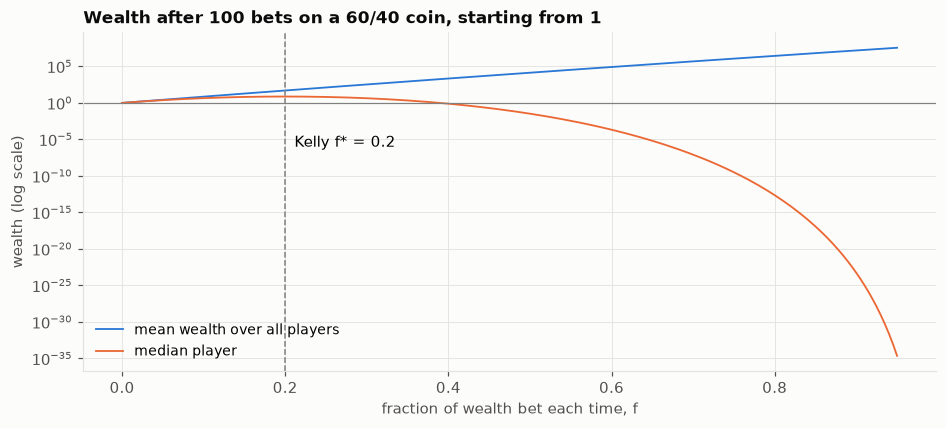

In [2]:
p, n_bets = 0.6, 100
f_grid = np.linspace(0.0, 0.95, 191)
mean_wealth = (1 + f_grid * (2 * p - 1)) ** n_bets
median_wealth = np.exp(n_bets * bet_growth(f_grid, p))

fig, ax = plt.subplots()
ax.semilogy(f_grid, mean_wealth, color=SERIES[0], label="mean wealth over all players")
ax.semilogy(f_grid, median_wealth, color=SERIES[1], label="median player")
ax.axvline(kelly_bet(p), color="0.5", lw=1, ls="--")
ax.axhline(1, color="0.5", lw=0.8)
ax.annotate("Kelly f* = 0.2", (kelly_bet(p), 1e-6), xytext=(6, 0), textcoords="offset points")
ax.set_title(f"Wealth after {n_bets} bets on a 60/40 coin, starting from 1")
ax.set_xlabel("fraction of wealth bet each time, f")
ax.set_ylabel("wealth (log scale)")
ax.legend(loc="lower left")
plt.show()

In [3]:
rng = np.random.default_rng(0)
n_players = 100_000
wins = rng.binomial(n_bets, p, n_players)
coin = pd.DataFrame(
    {
        f"f = {f:g}": {
            "mean wealth": np.mean(w := (1 + f) ** wins * (1 - f) ** (n_bets - wins)),
            "median wealth": np.median(w),
            "players losing money": np.mean(w < 1),
            "players left with < 1%": np.mean(w < 0.01),
            "share of total wealth held by top 1%": np.sort(w)[-n_players // 100 :].sum() / w.sum(),
        }
        for f in [0.1, 0.2, 0.4, 0.6, 0.9]
    }
).T
coin.style.format("{:.3g}")

,mean wealth,median wealth,players losing money,players left with < 1%,share of total wealth held by top 1%
f = 0.1,7.24,4.5,0.0622,0,0.0848
f = 0.2,50.5,7.49,0.179,0.00054,0.339
f = 0.4,2.15e+03,0.783,0.538,0.13,0.937
f = 0.6,1.7e+04,0.000214,0.91,0.693,1
f = 0.9,0.0421,5.31e-24,1,1,1


The mean rises steadily with $f$ while the median player is destroyed beyond $f = 0.4$
($2f^*$, where median growth is back to zero). At $f = 0.6$, 91% of players lose money
and the top 1% hold nearly all the wealth. At $f = 0.9$ the theoretical mean is
$1.18^{100} \approx 10^7$, yet the average over 100,000 simulated players is 0.04: the mean
is carried by outcomes rarer than one in 100,000, which no real player sees. Averaging over players
(ensemble average) and following one player through time (time average) give different
answers: the process is not ergodic. You only live one path, so the quantity to maximize is
the growth rate of that path, $E[\ln W]$, and that is the Kelly criterion. **H1 holds.**

## 2. Volatility drag on the S&P 500 (H2)

Hold $f$ times the S&P 500, rebalanced daily (borrowing at the T-bill rate when $f > 1$,
which is optimistic), and compare the realized growth with the parabola computed from the
sample $\mu$ and $\sigma$.

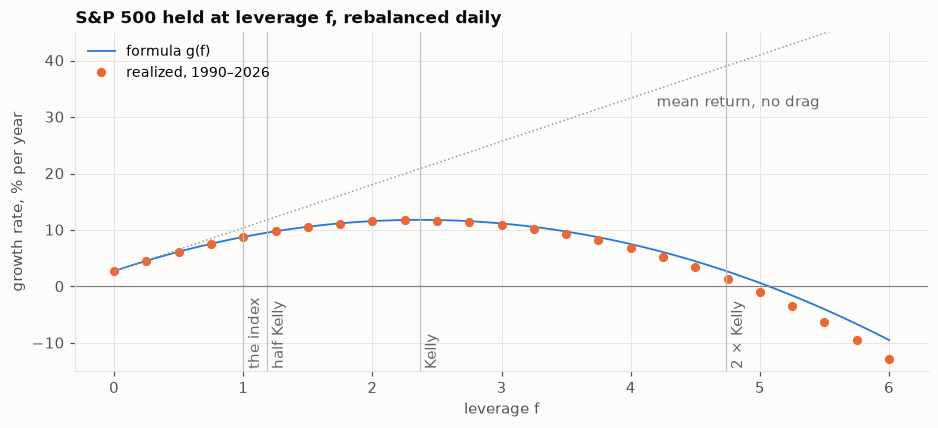

In [4]:
leverages = np.arange(0, 6.01, 0.25)
realized = [log_growth(leveraged_returns(r, f, rf=rf)) for f in leverages]
f_fine = np.linspace(0, 6, 601)

fig, ax = plt.subplots()
ax.plot(f_fine, growth_rate(f_fine, mu, sigma, r_cash) * 100, color=SERIES[0], label="formula g(f)")
ax.plot(
    leverages, np.array(realized) * 100, "o", ms=5, color=SERIES[1], label="realized, 1990–2026"
)
ax.plot(f_fine, (r_cash + f_fine * (mu - r_cash)) * 100, color="0.6", lw=1, ls=":")
ax.annotate("mean return, no drag", (4.2, (r_cash + 4.2 * (mu - r_cash)) * 100 - 3), color="0.4")
for f, name in [
    (1, "the index"),
    (f_star / 2, "half Kelly"),
    (f_star, "Kelly"),
    (2 * f_star, "2 × Kelly"),
]:
    ax.axvline(f, color="0.75", lw=0.8)
    ax.annotate(name, (f, -14), rotation=90, xytext=(3, 0), textcoords="offset points", color="0.4")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_ylim(-15, 45)
ax.set_title("S&P 500 held at leverage f, rebalanced daily")
ax.set_xlabel("leverage f")
ax.set_ylabel("growth rate, % per year")
ax.legend(loc="upper left")
plt.show()

In [5]:
spread = 0.01 / D  # a more realistic 1% per year above the T-bill rate on borrowed money
pd.DataFrame(
    {
        f"f = {f:.2f}": {
            "formula g(f)": growth_rate(f, mu, sigma, r_cash),
            "realized growth": log_growth(x := leveraged_returns(r, f, rf=rf)),
            "realized, 1% borrowing spread": log_growth(leveraged_returns(r, f, rf, spread)),
            "worst day": x.min(),
            "max drawdown": max_drawdown(x),
        }
        for f in [0.5, 1.0, f_star / 2, 2.0, f_star, 3.0, 2 * f_star]
    }
).T

,formula g(f),realized growth,"realized, 1% borrowing spread",worst day,max drawdown
f = 0.50,0.061,0.061,0.061,-0.064,-0.341
f = 1.00,0.088,0.088,0.088,-0.128,-0.596
f = 1.18,0.095,0.095,0.093,-0.151,-0.676
f = 2.00,0.116,0.115,0.105,-0.255,-0.912
f = 2.37,0.118,0.117,0.103,-0.302,-0.956
f = 3.00,0.112,0.109,0.089,-0.383,-0.988
f = 4.74,0.027,0.015,-0.023,-0.605,-1.000


The realized growth sits on the parabola up to about 3× leverage, then falls slightly below
it: fat tails (single days of −9% to −13% in 2008 and 2020) cost more than a Gaussian
$\sigma^2$ predicts. The arithmetic mean grows linearly with leverage, but compound growth
peaks at $f^* \approx 2.4$ and is below the cash rate by $2f^* \approx 4.7$. A realistic
1% borrowing spread lowers the peak further. The same drag explains why a 3× leveraged ETF
can lose money while its index rises.

Even in hindsight, full Kelly on the S&P 500 meant a −96% drawdown. The optimal growth rate
says nothing about the ride. **H2 holds.**

## 3. Estimating f* (H3)

The parabola above uses 37 years of hindsight. An investor in 1999 only had the past.

In [6]:
by_decade = {}
for start, end in [("1990", "1999"), ("2000", "2009"), ("2010", "2019"), ("2020", "2026")]:
    x, c = r.loc[start:end], rf.loc[start:end]
    by_decade[f"{start}–{end[-2:]}"] = {
        "Sharpe ratio": (x.mean() - c.mean()) / x.std() * np.sqrt(D),
        "Kelly f*": kelly_fraction(x.mean(), x.std(), c.mean()),
    }
pd.DataFrame(by_decade).T

,Sharpe ratio,Kelly f*
1990–99,0.838,5.931
2000–09,-0.163,-0.735
2010–19,0.823,5.563
2020–26,0.567,2.810


The Kelly fraction is the mean divided by the variance. The variance is estimated well,
but the mean is not. With $\hat\mu$ known to $\pm\sigma/\sqrt{T}$, the estimate
$\hat f = \hat\mu / \sigma^2$ has standard error

$$\mathrm{se}(\hat f) = \frac{1}{\sigma \sqrt{T}} ,$$

which is 1.8 for a 10-year window at $\sigma = 18\%$, and still 0.9 over the full 37 years.
The decade estimates range from −0.7 to 5.9.

Noise in the bet costs growth on average. Betting $c\hat f$ with $\hat f = f^* + \varepsilon$
and $\varepsilon \sim (0, \mathrm{se}^2)$:

$$E[g] - r = \sigma^2\left(c f^{*2} - \tfrac{c^2}{2}(f^{*2} + \mathrm{se}^2)\right),$$

maximized at $c = f^{*2}/(f^{*2} + \mathrm{se}^2)$, the gain of a Wiener filter with
signal-to-noise ratio $f^{*2}/\mathrm{se}^2$. Compare with holding the index ($f = 1$),
which needs no estimate at all.

In [7]:
def expected_excess_growth(c, f_true, se, sigma):
    """Expected growth above cash when betting c times a noisy estimate of f_true."""
    return sigma**2 * (c * f_true**2 - 0.5 * c**2 * (f_true**2 + se**2))


se10 = kelly_fraction_se(sigma, 10)
wiener = kelly_shrinkage(f_star, se10)
theory = (
    pd.Series(
        {
            "hold the index, f = 1": sigma**2 * (f_star - 0.5),
            "Kelly known exactly": sigma**2 * f_star**2 / 2,
            "estimated Kelly (10 years)": expected_excess_growth(1.0, f_star, se10, sigma),
            "estimated half Kelly": expected_excess_growth(0.5, f_star, se10, sigma),
            f"estimated Kelly × {wiener:.2f} (Wiener)": expected_excess_growth(
                wiener, f_star, se10, sigma
            ),
        }
    ).to_frame("expected growth above cash, % per year")
    * 100
)
theory

,"expected growth above cash, % per year"
"hold the index, f = 1",6.042
Kelly known exactly,9.074
estimated Kelly (10 years),4.074
estimated half Kelly,5.556
estimated Kelly × 0.64 (Wiener),5.850


Even if the S&P 500 were a stationary process with $f^* = 2.4$, ten years of data give a
Kelly estimate so noisy that betting it earns less than holding the index. The Wiener
shrinkage helps, but it needs the true $f^*$ to compute and still does not beat $f = 1$.

First check that this theory holds in a world where it should: resample the daily returns
with replacement (i.i.d., so stationary by construction, true $f^*$ = 2.4) into 500 paths of
37 years. Each year the investor re-estimates $\hat f$ from the trailing 10 years and holds
it for one year, long only ($\hat f \ge 0$).

In [8]:
WINDOW = 10


def trailing_kelly(x: np.ndarray, cash: float) -> np.ndarray:
    """Kelly fraction re-estimated each 252-day year from the trailing WINDOW years.

    x has shape (paths, years, 252). Returns (paths, years - WINDOW), the fraction held in
    each year from year WINDOW onward.
    """
    s1, s2 = x.sum(axis=2).cumsum(axis=1), (x**2).sum(axis=2).cumsum(axis=1)
    n = WINDOW * D
    m1 = (s1[:, WINDOW - 1 : -1] - np.pad(s1, ((0, 0), (1, 0)))[:, : -WINDOW - 1]) / n
    m2 = (s2[:, WINDOW - 1 : -1] - np.pad(s2, ((0, 0), (1, 0)))[:, : -WINDOW - 1]) / n
    return np.clip((m1 - cash) / (m2 - m1**2), 0, None)


rng = np.random.default_rng(1)
n_paths, n_years = 500, int(years)
cash_d = r_cash / D
sim = r.to_numpy()[rng.integers(0, len(r), (n_paths, n_years, D))]
f_hat = trailing_kelly(sim, cash_d)
test = sim[:, WINDOW:, :]


def sim_growth(frac: np.ndarray) -> np.ndarray:
    """Annual log growth of each path when holding frac (paths x years) of the index."""
    x = frac[:, :, None] * test + (1 - frac[:, :, None]) * cash_d
    with np.errstate(invalid="ignore"):
        return np.log1p(np.maximum(x, -1)).sum(axis=(1, 2)) / test.shape[1]


hold = sim_growth(np.ones_like(f_hat))
rules = {
    "hold the index, f = 1": np.ones_like(f_hat),
    "Kelly known exactly": np.full_like(f_hat, f_star),
    "estimated Kelly": f_hat,
    "estimated half Kelly": f_hat / 2,
    "estimated Kelly, capped at 2": np.minimum(f_hat, 2),
}
mc = {}
for name, frac in rules.items():
    g = sim_growth(frac)
    mc[name] = {
        "median growth above cash, %": (np.median(g) - r_cash) * 100,
        "paths growing slower than cash": np.mean(g < r_cash),
        "paths beating f = 1": np.mean(g > hold) if name != "hold the index, f = 1" else np.nan,
    }
pd.DataFrame(mc).T

,"median growth above cash, %",paths growing slower than cash,paths beating f = 1
"hold the index, f = 1",6.041,0.050,NaN
Kelly known exactly,9.045,0.172,0.700
estimated Kelly,2.151,0.368,0.278
estimated half Kelly,4.357,0.176,0.334
"estimated Kelly, capped at 2",6.391,0.190,0.568


The simulation agrees with the formula. In a stationary world with a genuine edge, the
re-estimated Kelly bet beats plain holding on only 28% of paths, and half Kelly on 33%: the
noise in $\hat\mu$ alone is enough. Even knowing $f^*$ exactly loses to $f = 1$ on 30% of
27-year paths. The one rule that helps is the cap at 2: it ignores the estimate exactly when
the estimate is most extreme. A cap is a prior ("leverage above 2 is never sensible"), and
priors beat noisy estimates.

Now the real history, where the process is not stationary either (same rule: trailing
10 calendar years, long only, re-estimated each January).

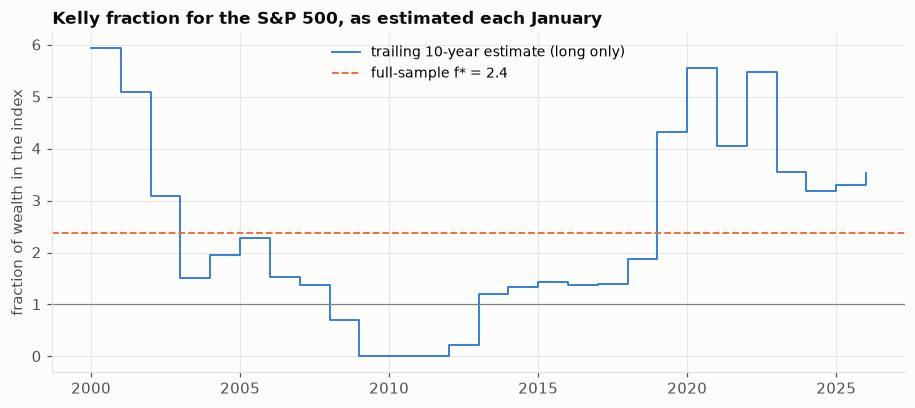

,"growth, % per year",volatility,max drawdown
"hold the index, f = 1",6.170,0.192,-0.596
Kelly in hindsight (cheating),5.878,0.456,-0.956
estimated Kelly,-11.002,0.644,-0.996
estimated half Kelly,1.341,0.322,-0.839
"estimated Kelly, capped at 2",5.560,0.297,-0.807


In [9]:
yearly = {}
for y in range(r.index[0].year + WINDOW, r.index[-1].year + 1):
    past = r.index.year.isin(range(y - WINDOW, y))
    yearly[y] = max(kelly_fraction(r[past].mean(), r[past].std(), rf[past].mean()), 0.0)
f_hat_real = pd.Series(r.index.year, index=r.index).map(yearly).dropna()
oos = r.loc[f_hat_real.index]
cash_oos = rf.loc[f_hat_real.index]

fig, ax = plt.subplots()
pd.Series(yearly).plot(
    ax=ax, drawstyle="steps-post", color=SERIES[0], label="trailing 10-year estimate (long only)"
)
ax.axhline(f_star, color=SERIES[1], ls="--", label=f"full-sample f* = {f_star:.1f}")
ax.axhline(1, color="0.5", lw=0.8)
ax.set_title("Kelly fraction for the S&P 500, as estimated each January")
ax.set_ylabel("fraction of wealth in the index")
ax.legend(loc="upper center")
plt.show()

real_rules = {
    "hold the index, f = 1": 1.0,
    "Kelly in hindsight (cheating)": f_star,
    "estimated Kelly": f_hat_real,
    "estimated half Kelly": f_hat_real / 2,
    "estimated Kelly, capped at 2": f_hat_real.clip(upper=2),
}
pd.DataFrame(
    {
        name: {
            "growth, % per year": log_growth(x := frac * oos + (1 - frac) * cash_oos) * 100,
            "volatility": x.std() * np.sqrt(D),
            "max drawdown": max_drawdown(x),
        }
        for name, frac in real_rules.items()
    }
).T

On the real path, from 2000 to 2026, estimated Kelly is a disaster. After the strong 1990s
the trailing estimate said "5× leverage" just before the dot-com crash; after the bad 2000s
it said "stay out" during the 2009–2012 rebound; after the strong 2010s it said 5–6×
leverage into the COVID crash. A trailing mean is a lagging estimate of a mean that changes
with the regime, so it bets most after good times. Even the capped rule and the hindsight
$f^*$ (which uses the 1990s to set leverage for 2000–2026) fall short of $f = 1$ here, with
drawdowns of −81% and −96%. **H3 holds**, more strongly than the stationary theory predicts.

## 4. The rebalancing bonus (H4)

Volatility drag also works in your favour. A portfolio's growth is
$g_p = \mu_p - \sigma_p^2/2$, and diversification cuts $\sigma_p^2$ below the average
variance of its assets while keeping the average mean. Writing each asset's growth as
$g_i = \mu_i - \sigma_i^2/2$:

$$g_p = \sum_i w_i g_i + \tfrac{1}{2}\Big(\sum_i w_i \sigma_i^2 - \sigma_p^2\Big).$$

The second term is the rebalancing bonus (also called the diversification return, or
"Shannon's demon": Shannon showed that rebalancing 50/50 between cash and a stock that goes
nowhere still makes money).

In [10]:
ASSETS = ["SPY", "EFA", "EEM", "TLT", "IEF", "GLD", "DBC", "VNQ"]
R = load_market_data(ASSETS, currency="EUR").returns()[ASSETS].loc["2007-03-01":].dropna()
w = np.full(len(ASSETS), 1 / len(ASSETS))
cov = R.cov().to_numpy() * D
asset_growth = pd.Series({a: log_growth(R[a]) for a in ASSETS})

pd.DataFrame(
    {
        "mean return μ": R.mean() * D,
        "volatility σ": R.std() * np.sqrt(D),
        "growth g = log growth": asset_growth,
    }
).T

,SPY,EFA,EEM,TLT,IEF,GLD,DBC,VNQ
mean return μ,0.113,0.056,0.056,0.035,0.039,0.096,0.034,0.058
volatility σ,0.213,0.225,0.284,0.191,0.134,0.202,0.207,0.301
growth g = log growth,0.091,0.030,0.016,0.017,0.030,0.075,0.013,0.012


In [11]:
def drifting_mix(returns: pd.DataFrame, weights: np.ndarray, freq: str | None) -> pd.Series:
    """Wealth of a mix rebalanced to fixed weights at each new period (None: never)."""
    period = returns.index.to_period(freq) if freq else np.zeros(len(returns))
    holdings, values, prev = weights.copy(), [], period[0]
    for p_, row in zip(period, returns.to_numpy(), strict=True):
        if p_ != prev:
            holdings, prev = weights * holdings.sum(), p_
        holdings = holdings * (1 + row)
        values.append(holdings.sum())
    return pd.Series(values, index=returns.index)


bonus = rebalancing_bonus(w, cov)
check = {
    "average asset growth Σ w g": asset_growth @ w,
    "rebalancing bonus (formula)": bonus,
    "predicted mix growth": asset_growth @ w + bonus,
}
for name, freq in [
    ("rebalanced daily", "D"),
    ("rebalanced monthly", "M"),
    ("rebalanced yearly", "Y"),
    ("buy and hold, never rebalanced", None),
]:
    v = drifting_mix(R, w, freq)
    check[name] = np.log(v.iloc[-1]) / (len(R) / D)
pd.Series(check).to_frame("growth, % per year") * 100

,"growth, % per year"
average asset growth Σ w g,3.538
rebalancing bonus (formula),1.376
predicted mix growth,4.914
rebalanced daily,4.921
rebalanced monthly,4.459
rebalanced yearly,4.771
"buy and hold, never rebalanced",4.464


Equal weights over these 8 assets earn a bonus of 1.4% per year over their average
growth, and the daily rebalanced mix matches the prediction to 0.01%. **H4 holds.**

The bonus is measured against the average asset, not against buy-and-hold. Over 2007–2026
the never-rebalanced portfolio grew as fast as the monthly rebalanced one: left alone, it
let the two best assets (US stocks and gold) take over, and that trend among assets was
worth about as much as the bonus. Rebalancing wins when assets mean-revert relative to each
other and loses when one keeps outperforming; nobody knows in advance which regime is coming.
The gaps of up to 0.5%/yr between rebalancing frequencies follow no order (yearly beats
monthly, daily beats both) and look like noise rather than a rule.

## 5. Conclusions

| | Finding |
|---|---|
| H1 | Maximizing expected wealth ruins the typical player; Kelly maximizes the growth of the path you actually live. |
| H2 | Growth follows $g(f) = r + f(\mu - r) - f^2\sigma^2/2$ on 37 years of S&P 500, slightly worse at high leverage because of fat tails. |
| H3 | The Kelly fraction cannot be estimated well enough to use: se = $1/(\sigma\sqrt{T})$ ≈ 1.8 for 10 years. Estimated Kelly loses to holding the index even in a stationary simulation, and much worse in real history (−11%/yr against +6%/yr since 2000). Capping leverage helps in simulation but not in history. |
| H4 | Rebalancing turns volatility drag into a bonus over the average asset (1.4%/yr here), but not necessarily over buy-and-hold. |

**What this means for the hobby account**

- Holding the index unleveraged ($f = 1$) is about 0.4 × the hindsight Kelly fraction for
  stocks: a sensible place to sit given that $f^*$ is unknowable. No leverage, and no
  leveraged ETFs held for the long run.
- Use Kelly as an upper bound, never a target. For a strategy with Sharpe ratio SR and
  volatility σ, $f^* = \mathrm{SR}/\sigma$, and with backtest Sharpe ratios being optimistic
  (notebook 002), bet a small fraction of it.
- Volatility is not just risk, it is a direct cost to compound growth. Cutting $\sigma$
  at equal mean (diversification, risk parity) raises growth; this is part of why the
  risk-parity trend strategy of notebook 003 compounded better than its Sharpe ratio alone
  suggests.
- Next idea: with a constant mean, Kelly says hold $f_t \propto 1/\sigma_t^2$, where
  $\sigma_t$ is the volatility forecast of notebook 001. Volatility targeting
  ($f_t \propto 1/\sigma_t$) is a damped version of this. Testing which exponent works best
  only needs the volatility forecast, which is the part that can be predicted.